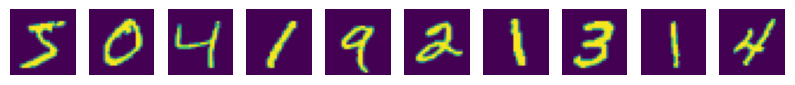

In [1]:
import torchvision.datasets as datasets
import torchvision.transforms.v2 as transforms
import torch
import matplotlib.pyplot as plt

transform = transforms.Compose([
    transforms.ToImage(),
    transforms.Lambda(lambda x: x[0]),
    transforms.ToDtype(torch.float32, scale=True)
])

ds = datasets.MNIST(
    "./data",
    download=True,
    transform=transform
)

fig, ax = plt.subplots(1, 10, figsize=(10, 1))
for i in range(10):
    X, y = ds[i]
    ax[i].imshow(X)
    ax[i].axis("off")

In [2]:
import torch.nn as nn
import copy
from torch.utils.data import DataLoader
from tqdm import tqdm

EPOCHS = 5
EMA_ALPHA = 0.98

dead_layer = nn.Linear(28 * 28, 10)
with torch.no_grad():
    dead_layer.weight.copy_(-dead_layer.weight.abs())
    dead_layer.bias.copy_(-dead_layer.bias.abs())

model = nn.Sequential(
    nn.Flatten(),
    copy.deepcopy(dead_layer),
    nn.ReLU()
)

optim = torch.optim.Adam(model.parameters())
loss_fn = nn.CrossEntropyLoss()

dl = DataLoader(ds, batch_size=32)
loss_ema = None
for _ in range(EPOCHS):
    with tqdm(dl) as pbar:
        for X, y in pbar:
            loss = loss_fn(model(X), y)

            optim.zero_grad()
            loss.backward()
            optim.step()

            loss_ema = loss.item() if loss_ema is None else EMA_ALPHA * loss_ema + (1 - EMA_ALPHA) * loss.item()
            pbar.set_postfix({"loss": loss_ema})

100%|██████████| 1875/1875 [00:04<00:00, 434.78it/s, loss=2.3]


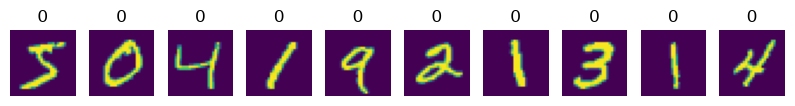

In [3]:
fig, ax = plt.subplots(1, 10, figsize=(10, 1))
for i in range(10):
    X, y = ds[i]
    with torch.no_grad():
        ax[i].set_title(model(X[None]).argmax().item())
    ax[i].imshow(X)
    ax[i].axis("off")

In [4]:
leakyrelu_model = nn.Sequential(
    nn.Flatten(),
    copy.deepcopy(dead_layer),
    nn.LeakyReLU()
)

optim = torch.optim.Adam(leakyrelu_model.parameters())

for _ in range(EPOCHS):
    with tqdm(dl) as pbar:
        for X, y in pbar:
            loss = loss_fn(leakyrelu_model(X), y)

            optim.zero_grad()
            loss.backward()
            optim.step()

            loss_ema = loss.item() if loss_ema is None else EMA_ALPHA * loss_ema + (1 - EMA_ALPHA) * loss.item()
            pbar.set_postfix({"loss": loss_ema})

100%|██████████| 1875/1875 [00:04<00:00, 426.57it/s, loss=0.188]


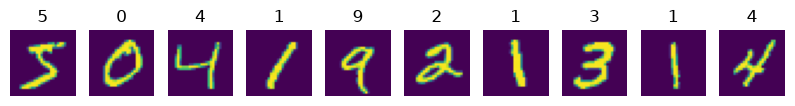

In [5]:
fig, ax = plt.subplots(1, 10, figsize=(10, 1))
for i in range(10):
    X, y = ds[i]
    with torch.no_grad():
        ax[i].set_title(leakyrelu_model(X[None]).argmax().item())
    ax[i].imshow(X)
    ax[i].axis("off")